# CMPS458: Reinforcement Learning - Fall 2026
## Assignment 1: Exploration vs. Exploitation

**Name:** `Ahmed Farouk - Omar Ashraf`  **Code:** `1220223 - 1220132`


---
## How this notebook works

Every reinforcement learning agent faces the same dilemma: **exploit** what it already knows to earn reward now, or **explore** to find out whether something better exists? In this assignment you will build small learning agents, watch this dilemma play out in experiments, and explain what you see.

You will see three kinds of cells:

| Symbol | What you do |
|---|---|
| 🛠️ **Write a function** | Fill in the body of a Python function (replace `raise NotImplementedError`). |
| ✅ **Test cell** | Run it to check your function. Passing the tests does not guarantee full marks, but failing them means something is wrong. |
| ✏️ **Concept question** | Answer in your own words in the markdown cell below the question. Short and precise beats long and vague. |

Cells marked **"Provided"** are complete. Read them, run them, but you do not need to edit them.

**Rules of thumb:** run the notebook from top to bottom; use *Kernel → Restart & Run All* before you submit to make sure everything works; do not change function names or signatures.

### Grading (100 points)

| Part | Topic | Points |
|---|---|---|
| 1 | Warm-up: why exploring matters | 15 |
| 2 | Building a bandit agent (greedy and ε-greedy) | 28 |
| 3 | Optimistic initial values | 10 |
| 4 | Upper Confidence Bound (UCB) | 10 |
| 5 | When the world changes (non-stationary bandits) | 10 |
| 6 | Exploration when actions have delayed effects (RiverSwim) | 16 |
| 7 | Reflection | 6 |
| 8 | decaying ε | 5 |

### Formulas you will need

* **Incremental sample average** (after the arm has been pulled $n$ times, including the latest pull): $\;Q \leftarrow Q + \dfrac{1}{n}\,(R - Q)$
* **Constant step size** $\alpha$: $\;Q \leftarrow Q + \alpha\,(R - Q)$
* **ε-greedy:** with probability $\varepsilon$ pick a random arm, otherwise pick the arm with the highest $Q$.
* **UCB:** $\;A_t = \arg\max_a \left[\, Q_t(a) + c\sqrt{\dfrac{\ln t}{N_t(a)}}\,\right]$, where $N_t(a)$ is how often arm $a$ has been pulled so far.
* **Regret** at one step $=$ (value of the best arm) $-$ (true value of the arm you pulled). Cumulative regret is the running sum. Lower is better.
* **Q-learning:** $\;Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,\big]$

---
## Part 0: Setup and provided code

Run the cells below. They import libraries, set the experiment size, and define the *multi-armed bandit* environment you will use throughout.

**The 10-armed testbed.** Imagine 10 slot machines ("arms"). Arm $a$ has a hidden true average payout $q^*(a)$, drawn from a normal distribution with mean 0 and standard deviation 1. Each time you pull arm $a$, you receive a noisy reward drawn from a normal distribution centered at $q^*(a)$ (standard deviation 1). You do not know which arm is best; you must find out by pulling.

*Provided: do not edit.*

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3})

SEED    = 42     # fixed seed => reproducible results
K       = 10     # number of arms
N_RUNS  = 200    # how many independent bandit problems we average over (lower = faster)
N_STEPS = 1000   # how many pulls per problem


def run_test(test_fn):
    # Runs one of the test functions below and prints a friendly message.
    try:
        test_fn()
    except NotImplementedError:
        print(f"⚠️  {test_fn.__name__}: function not implemented yet")
    except AssertionError as e:
        print(f"❌ {test_fn.__name__} failed: {e}")
    except Exception as e:
        print(f"❌ {test_fn.__name__} crashed with {type(e).__name__}: {e}")

In [4]:
class GaussianBandit:
    # A K-armed bandit whose arm values q_star[a] are hidden from the agent.
    #   drift_std > 0  makes the world change over time (used in Part 5).
    #   equal_start    starts every arm at value 0 (used in Part 5).

    def __init__(self, k, rng, drift_std=0.0, equal_start=False):
        self.k = k
        self.rng = rng
        self.drift_std = drift_std
        self.q_star = np.zeros(k) if equal_start else rng.normal(0.0, 1.0, size=k)

    @property
    def best_arm(self):
        return int(np.argmax(self.q_star))

    @property
    def best_value(self):
        return float(np.max(self.q_star))

    def pull(self, arm):
        # Return a noisy reward. If drift_std > 0, all true values then take a small random step.
        reward = self.rng.normal(self.q_star[arm], 1.0)
        if self.drift_std > 0:
            self.q_star += self.rng.normal(0.0, self.drift_std, size=self.k)
        return reward


# Quick look at one random bandit problem:
demo = GaussianBandit(K, np.random.default_rng(0))
print("True arm values:", np.round(demo.q_star, 2))
print("Best arm:", demo.best_arm, "with value", round(demo.best_value, 2))

True arm values: [ 0.13 -0.13  0.64  0.1  -0.54  0.36  1.3   0.95 -0.7  -1.27]
Best arm: 6 with value 1.3


---
# Part 1: Warm-up: why exploring matters (15 points)

### 1.1 In your own words (3 points)

Explain what **exploration** and **exploitation** mean in reinforcement learning. Then give **one everyday example** (not from computing, for example choosing what to eat for lunch) that shows the dilemma between them. *(About 80 to 120 words.)*

**✏️ Your answer:**

- Exploration: Exploring other states in current situation even though you have a stable good option in hopes to find an option that will play out better in the long run.

- Exploitation: You know a good option, so you keep going for it.

- Example:
Farouk and I love eating from Anas El Demeshky Restaurant. Their food is reliable. If I keep on eating Anas Everyday, then I am exploiting. However, if I try to go for a new restaurant that has a good offer/newly opened in hopes that this restaurant might have a better meal/category of foods, then that would be exploration. 

### 1.2 The danger of committing too early (4 points)

You are offered two unfair coins. A pays \$1 for heads and B pays \$1 for heads. You do not know that

* coin **A** lands heads with probability **0.8** (the better coin), and
* coin **B** lands heads with probability **0.4**.

Your strategy: flip **each coin exactly once**, then **commit forever** to the coin that paid more. If both paid the same, choose between them with a fair coin flip.

**(a)** What is the probability that both coins **A** & **B** fall on *Heads*?

**✏️ Your answer:**

- Probability that both coins land on heads = 0.8*0.4 = 0.32

**(b)** What is the probability that both coin **A** falls on *Heads* & **B** falls on *Tails*?

**✏️ Your answer:**

probability of A landing on heads with B falling on Tails = 0.8 * (1 - 0.4) = 0.8 * 0.6 = 0.48

**(c)** What is the probability that both coin **A** falls on *Tails* & **B** falls on *Heads*?

**✏️ Your answer:**

probability of A falling on Tails and B falling on Heads = (1 - 0.8) * 0.4 = 0.2 * 0.4 = 0.08

**(d)** What is the probability that both coins **A** & **B** fall on *Tails*?

**✏️ Your answer:**

probability that both fall on tails = (1 - 0.8) * (1 - 0.4) = 0.2 * 0.6 = 0.12

**(e)** What is the probability that you **commit** to coin **B**? *(i.e. Flip both coins and choose coin B)*

**✏️ Your answer:**

- To commit to B, it needs to fall on Heads & A to fall on tails OR Both fell on Heads first time, then we chose B after the fair coin flip (since it was the winner) OR Both fell on tails first time then fair coin flip decided B too.

- Probability of B falling on heads, and A falling on tails = 0.08

- Probability of both landing on heads = 0.32

- Probability of fair coin flip landing on Heads (We chose Heads for B) = 0.5

- Probability of both landing on tails = 0.12

- Total = 0.08 + (0.32 + 0.12) * 0.5 = 0.3

**(f)** In one or two sentences, what does this tell you about exploiting after very little exploration?

**✏️ Your answer:**

Here, we learned that with very little exploration, we have a 30% chance that we will commit to Coin B (Which is the bad option). However, if we have given enough time to explore more, we could have became sure that coin A is the better option in the long run.

### 1.3 🛠️ Check your calculation by simulation (4 points)

Write `simulate_lock_in(n_trials, rng)`, which repeats the experiment of 1.2 `n_trials` times and returns the **fraction of trials in which you commit to coin B**. It should be close to your answer from 1.2(b).

- Repeat for **n** trials
- Flip coin **A**
- Flip coin **B**
- If both coins fall on the *same face*, choose **randomly**
- Else select coin that fell on *Heads*
- Accumulate number of iterations where coin **B** is chosen

*Hints: `rng.random()` gives a uniform number in [0, 1). Coin A shows heads if `rng.random() < 0.8`. You may use a loop or NumPy arrays.*

In [5]:
def simulate_lock_in(n_trials, rng):
    # Return the fraction of trials in which we commit to coin B (heads prob 0.4)
    # after flipping A (heads prob 0.8) and B once each.
    # Rule: commit to the coin that paid more; if tied, choose by a fair coin flip.
    coin_b_success_count = 0
    # TODO: your code here
    for i in range(n_trials):
        coin_a = rng.random() < 0.8
        coin_b = rng.random() < 0.4
        if (coin_a and coin_b) or (not coin_a and not coin_b) :
            fair_flip = rng.random() < 0.5
            if fair_flip:
                coin_b_success_count += 1
        elif coin_b:
            coin_b_success_count += 1
    return coin_b_success_count / n_trials


In [6]:
# ✅ Test cell
def test_simulate_lock_in():
    frac = simulate_lock_in(20000, np.random.default_rng(1))
    assert 0.27 < frac < 0.33, f"expected a value close to your answer to 1.2(b) (about 0.30), got {frac:.3f}"
    print(f"✅ simulate_lock_in passed (simulated probability = {frac:.3f})")

run_test(test_simulate_lock_in)

✅ simulate_lock_in passed (simulated probability = 0.298)


### 1.4 What is regret? (2 points)

In the lecture, we used reward and return to measure performance.

However, **cumulative regret** is used in a bandit problem. Search for the term and explain in your own words what it is, and why it can be a fairer measure than just looking at the total reward collected. *(About 50 to 80 words.)*

**✏️ Your answer:**

- We searched and knew that cumulative regret is the difference between the reward you could have got if you chose the optimal option and the reward of the option you chose.
- If we kept exploring forever, we will keep accumulating regret forever since we will choose sub optimal options as we go.
- If we kept exploiting forever from the beginning, we will also accumulate regret forever in a linear manner.
- Since our environment is unknown, we can't possibly know the optimal options to choose, and therefore zero regret isn't possible. So our target is a decaying/flattening regret
- After exploring to know the optimal policy we should exploit it.

### 1.5 The role of ε (2 points)

An ε-greedy agent picks a random arm with probability ε, otherwise it picks the best-looking arm.

Describe what happens if **ε = 0**, if **ε = 1**, and if ε is a small constant such as 0.1 that **never changes**. Why might a constant ε = 0.1 still waste reward in the long run? *(About 80 to 120 words.)*

**✏️ Your answer:**

- If epsillon = 0. That means we are telling the agent to never explore, just be greedy and exploit which could lead to it being stuck in a local optimum loop.

- If epsillon = 1. That means we are telling the agent to always explore, so now the agent will never learn.

- If epsillon is small (0.1) and never changes, we only have a 10% chance to explore other options which is a small probability compared to 90% of exploiting.

- Why might this be a problem? Because after knowing the optimal policy we want to always exploit, however a constant 0.1 epsillon will still make the agent explore other options even though we already know that they are sub optimal. 

---
# Part 2: Building a bandit agent (28 points)

In this part you will write the building blocks of an ε-greedy agent and the loop that lets it interact with a bandit.

### 2.1 🛠️ Breaking ties randomly (2 points)

Write `argmax_random_ties(values, rng)`. It returns the index of the largest entry of `values`. If several entries share the maximum, pick **one of them uniformly at random**.

> **Why not just use `np.argmax`?** `np.argmax` always returns the *first* maximum. At the start of a run all estimates are equal (for example all 0), so an agent using `np.argmax` would always pull arm 0 first: a hidden bias that quietly damages your results.

*Hints: `np.flatnonzero(condition)` returns the indices where a condition is true; `rng.choice(list_of_indices)` picks one at random. Return a plain `int`.*

In [7]:
def argmax_random_ties(values, rng):
    # Index of the maximum of `values`; ties are broken uniformly at random.

    # TODO: your code here
    max_val = max(values)
    condition_mask = []
    for i in range(len(values)):
        condition_mask.append(True if values[i] == max_val else False)
    true_indices = np.flatnonzero(condition_mask)
    return rng.choice(true_indices)


In [8]:
# ✅ Test cell
def test_argmax_random_ties():
    rng = np.random.default_rng(0)
    assert argmax_random_ties(np.array([1.0, 5.0, 2.0]), rng) == 1, "should return the index of the largest value"
    picks = np.array([argmax_random_ties(np.array([1.0, 3.0, 3.0, 2.0]), rng) for _ in range(2000)])
    assert set(picks) == {1, 2}, "with a tie between indices 1 and 2, only those two may be returned"
    frac = np.mean(picks == 1)
    assert 0.4 < frac < 0.6, f"ties must be broken uniformly at random; index 1 was chosen {frac:.0%} of the time"
    picks = {argmax_random_ties(np.zeros(5), rng) for _ in range(500)}
    assert picks == {0, 1, 2, 3, 4}, "when all values are equal, every index should be possible"
    print("✅ argmax_random_ties passed")

run_test(test_argmax_random_ties)

✅ argmax_random_ties passed


### 2.2 🛠️ ε-greedy action selection (4 points)

Write `epsilon_greedy_action(Q, epsilon, rng)`:

* with probability `epsilon`, return a **uniformly random** arm (any of the `len(Q)` arms, including the best one);
* otherwise return the arm with the highest estimate, using your `argmax_random_ties`.

*Hint: `rng.random()` is uniform in [0, 1); `rng.integers(n)` returns a random integer from 0 to n−1.*

In [9]:
def epsilon_greedy_action(Q, epsilon, rng):
    # Q: array of current value estimates (one per arm).

    # TODO: your code here
    if rng.random() < epsilon: # We will Explore
        return rng.integers(len(Q))
    else: # We will exploit
        best_arm_index = argmax_random_ties(Q, rng)
        return best_arm_index


In [10]:
# ✅ Test cell
def test_epsilon_greedy_action():
    rng = np.random.default_rng(1)
    Q = np.array([0.0, 2.0, 1.0, 0.5])
    picks = [epsilon_greedy_action(Q, 0.0, rng) for _ in range(500)]
    assert all(p == 1 for p in picks), "with epsilon = 0 the agent must always pick the best arm (index 1)"
    picks = np.array([epsilon_greedy_action(Q, 1.0, rng) for _ in range(4000)])
    freq = np.bincount(picks, minlength=4) / 4000
    assert np.all(np.abs(freq - 0.25) < 0.05), f"with epsilon = 1 each arm should be chosen ~25% of the time, got {freq.round(2)}"
    picks = np.array([epsilon_greedy_action(Q, 0.2, rng) for _ in range(10000)])
    frac_best = np.mean(picks == 1)
    assert 0.80 < frac_best < 0.90, f"with epsilon = 0.2 and 4 arms the best arm should be chosen ~85% of the time, got {frac_best:.2f}"
    print("✅ epsilon_greedy_action passed")

run_test(test_epsilon_greedy_action)

✅ epsilon_greedy_action passed


### 2.3 🛠️ Learning from a reward: the sample average (4 points)

After each pull the agent must update its estimate of the arm it just pulled. Write `update_sample_average(Q, N, arm, reward)` so that `Q[arm]` becomes the average of all rewards seen from that arm, using the **incremental formula**

$$Q \leftarrow Q + \frac{1}{n}\,(R - Q),$$

where $n$ = `N[arm]`.

**Convention used throughout this notebook:** the main loop increases `N[arm]` by 1 **before** it calls your update function, so inside the function `N[arm]` already includes the current pull. Modify `Q` **in place** (do not return anything).

In [11]:
def update_sample_average(Q, N, arm, reward):
    # Update Q[arm] in place using the incremental sample average.
    # N[arm] already counts the current pull.

    # TODO: your code here
    Q[arm] = Q[arm] + (1 / N[arm]) * (reward - Q[arm])

In [12]:
# ✅ Test cell
def test_update_sample_average():
    Q = np.array([0.0, 0.0]); N = np.array([1, 0])
    update_sample_average(Q, N, 0, 4.0)
    assert np.isclose(Q[0], 4.0), "after the first reward the estimate should equal that reward (average of one number)"
    N[0] = 2; update_sample_average(Q, N, 0, 2.0)
    assert np.isclose(Q[0], 3.0), f"average of 4 and 2 is 3, got {Q[0]}"
    N[0] = 3; update_sample_average(Q, N, 0, 6.0)
    assert np.isclose(Q[0], 4.0), f"average of 4, 2 and 6 is 4, got {Q[0]}"
    assert Q[1] == 0.0, "only the pulled arm should change"
    print("✅ update_sample_average passed")

run_test(test_update_sample_average)

✅ update_sample_average passed


### 2.4 🛠️ The main loop (6 points)

Now put the pieces together. Write `run_one_bandit(...)`, which lets an agent play `n_steps` pulls on **one** bandit problem.

The agent is described by two functions you pass in:

* `action_fn(Q, N, t, rng)` returns the arm to pull. (`t` is the step number, starting at **1**.)
* `update_fn(Q, N, arm, reward)` updates `Q` in place.

Your loop should, for every step:

1. Choose an arm with `action_fn`.
2. **Before pulling**, record whether that arm is the best arm (`bandit.best_arm`) and the **regret** of this step: `bandit.best_value - bandit.q_star[arm]`.
   *(Why before? In Part 5 the true values drift after each pull, so measure them first.)*
3. Pull the arm with `bandit.pull(arm)` to get the reward.
4. Increase `N[arm]` by 1, **then** call `update_fn`.
5. Store the reward.

Return three NumPy arrays of length `n_steps`: `rewards`, `is_optimal` (1.0 if the best arm was pulled, else 0.0), and `regret` (per-step regret).

In [13]:
def run_one_bandit(bandit, action_fn, update_fn, q_init, n_steps, rng):
    Q = np.full(bandit.k, q_init, dtype=float)   # value estimates, all start at q_init
    N = np.zeros(bandit.k, dtype=int)            # how often each arm has been pulled

    rewards    = np.zeros(n_steps)
    is_optimal = np.zeros(n_steps)
    regret     = np.zeros(n_steps)

    # TODO: your code here (loop over the steps)
    for i in range(n_steps):
        chosen_arm_index = action_fn(Q, N, i + 1, rng)
        if bandit.best_arm != chosen_arm_index:
            regret[i] = bandit.best_value - bandit.q_star[chosen_arm_index]
        else:
            is_optimal[i] += 1
        rewards[i] = bandit.pull(chosen_arm_index)
        N[chosen_arm_index] += 1
        update_fn(Q, N, chosen_arm_index, rewards[i])

    return rewards, is_optimal, regret

In [14]:
# ✅ Test cell
def test_run_one_bandit():
    def make():
        b = GaussianBandit(3, np.random.default_rng(0)); b.q_star = np.array([0.0, 1.0, 2.0]); return b

    # Agent that always pulls the worst arm (index 0): regret is 2 every step, never optimal.
    r, o, g = run_one_bandit(make(), lambda Q, N, t, rng: 0, lambda Q, N, a, x: None, 0.0, 50, np.random.default_rng(1))
    assert r.shape == o.shape == g.shape == (50,), "all three returned arrays must have length n_steps"
    assert np.allclose(g, 2.0) and np.allclose(o, 0.0), "always pulling the worst arm: regret should be 2.0 and is_optimal 0.0 at every step"

    # Agent that always pulls the best arm (index 2): regret 0, always optimal, rewards near 2.
    r, o, g = run_one_bandit(make(), lambda Q, N, t, rng: 2, lambda Q, N, a, x: None, 0.0, 500, np.random.default_rng(1))
    assert np.allclose(g, 0.0) and np.allclose(o, 1.0), "always pulling the best arm: regret should be 0 and is_optimal 1"
    assert 1.8 < r.mean() < 2.2, "rewards should be noisy samples around the arm's true value (2.0)"

    # The update function must see N already increased, and the step counter t must start at 1.
    seen_N, seen_t = [], []
    def act(Q, N, t, rng): seen_t.append(t); return 1
    def upd(Q, N, a, x): seen_N.append(int(N[a]))
    run_one_bandit(make(), act, upd, 0.0, 5, np.random.default_rng(1))
    assert seen_N == [1, 2, 3, 4, 5], f"N[arm] must be increased BEFORE update_fn is called; update_fn saw {seen_N}"
    assert seen_t == [1, 2, 3, 4, 5], f"t should start at 1; action_fn saw {seen_t}"

    # Estimates start at q_init.
    seen_Q = []
    run_one_bandit(make(), lambda Q, N, t, rng: (seen_Q.append(Q.copy()), 0)[1], lambda Q, N, a, x: None, 7.5, 1, np.random.default_rng(1))
    assert np.allclose(seen_Q[0], 7.5), "estimates should start at q_init"
    print("✅ run_one_bandit passed")

run_test(test_run_one_bandit)

✅ run_one_bandit passed


### 2.5 Running the experiment (4 points)

*Provided: do not edit.* The helper `run_many` repeats `run_one_bandit` on `N_RUNS` different random bandit problems and averages the results (all agents face the *same* problems, so the comparison is fair). The `eps_greedy(ε)` helper packages your function into an agent.

We compare three agents:

* **greedy** (ε = 0): never explores;
* **ε = 0.01**: explores 1% of the time;
* **ε = 0.1**: explores 10% of the time.

All start with estimates $Q = 0$ and use your sample-average update.

In [15]:
def run_many(action_fn, update_fn, q_init=0.0, n_runs=N_RUNS, n_steps=N_STEPS,
             drift_std=0.0, equal_start=False, seed=SEED):
    # Average run_one_bandit over many independent problems. Returns a dict of curves.
    R = np.zeros((n_runs, n_steps)); O = np.zeros((n_runs, n_steps)); G = np.zeros((n_runs, n_steps))
    for i in range(n_runs):
        bandit = GaussianBandit(K, np.random.default_rng([seed, i, 0]), drift_std, equal_start)
        R[i], O[i], G[i] = run_one_bandit(bandit, action_fn, update_fn, q_init, n_steps,
                                          np.random.default_rng([seed, i, 1]))
    return {"reward": R.mean(axis=0),                       # average reward at each step
            "optimal": 100 * O.mean(axis=0),                # % of runs pulling the best arm at each step
            "regret": np.cumsum(G, axis=1).mean(axis=0)}    # cumulative regret, averaged over runs


# Agent "builders": they package your functions into the form run_many expects.
def eps_greedy(epsilon):
    return lambda Q, N, t, rng: epsilon_greedy_action(Q, epsilon, rng)


def plot_all(results, title=""):
    # Three panels: average reward, % optimal action, cumulative regret.
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, metric, ylabel in zip(axes, ["reward", "optimal", "regret"],
                                  ["Average reward", "% optimal action", "Cumulative regret"]):
        for label, res in results.items():
            ax.plot(res[metric], label=label)
        ax.set_xlabel("Step"); ax.set_ylabel(ylabel)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()


def print_summary(results, last=100):
    print(f"{'agent':<28}{'avg reward':>12}{'% optimal':>12}{'total regret':>15}")
    print(f"{'':<28}{f'(last {last})':>12}{f'(last {last})':>12}{'(final)':>15}")
    for label, res in results.items():
        print(f"{label:<28}{res['reward'][-last:].mean():>12.2f}{res['optimal'][-last:].mean():>12.1f}{res['regret'][-1]:>15.1f}")

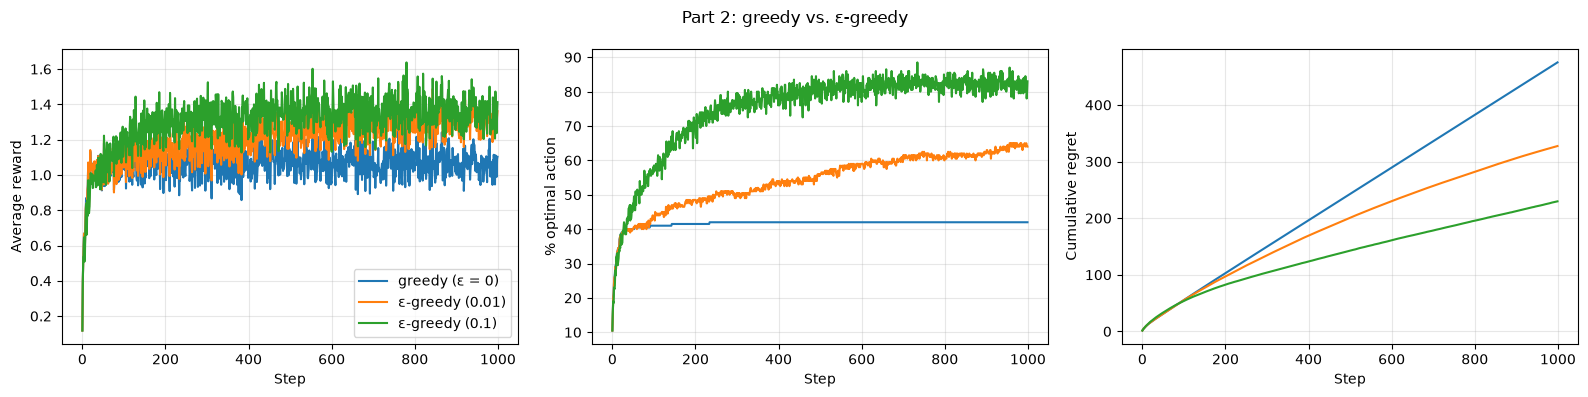

agent                         avg reward   % optimal   total regret
                              (last 100)  (last 100)        (final)
greedy (ε = 0)                      1.06        42.0          475.1
ε-greedy (0.01)                     1.31        63.6          327.4
ε-greedy (0.1)                      1.35        82.3          229.7


In [16]:
results_p2 = {
    "greedy (ε = 0)":  run_many(eps_greedy(0.0),  update_sample_average),
    "ε-greedy (0.01)": run_many(eps_greedy(0.01), update_sample_average),
    "ε-greedy (0.1)":  run_many(eps_greedy(0.1),  update_sample_average),
}
plot_all(results_p2, "Part 2: greedy vs. ε-greedy")
print_summary(results_p2)

### 2.6 📝 Analysing what you see (8 points)

Use your plots and the summary table to answer.

**(a)** *(3 pts)* Look at the graph plot generated in 2.5.
- Which agent is best early on (first 50 steps), 
- and which is best at step 1000 (in % optimal and in regret)?
- Explain *why* the ranking changes (or does not).

**✏️ Your answer:**

- The greedy with epsillon = 0 is the best early on, since it is already choosing a sub optimal choice while other agents might be exploring. So early on, it will have the least regret and highest % optimal action, and highest average reward.
- At step 1000, the agent with epsillon = 1 is the best since it has the best numbers among all of the other agents. Reason is in the bullet point beneath.
- The ranking changed because of the exploration factor, since we have learned an optimal choice.

**(b)** *(2 pts)* The greedy agent's "% optimal action" curve flattens at a low value. Explain why greedy gets stuck, in the language of exploration and exploitation.

**✏️ Your answer:**

Because he never explored to learn a better choice.

**(c)** *(3 pts)* An ε-greedy agent with ε = 0.1 and 10 arms can never exceed a certain "% optimal action", even if it knew exactly which arm is best. Compute this ceiling (remember that a random exploratory pull can also land on the best arm). Then predict: after **100,000** steps, which of the ε = 0.01 and ε = 0.1 agents would have the higher % optimal action? Explain.

**✏️ Your answer:**
- It can never exceed that percentage, because even after knowing the optimal action, we still have a 10% chance that we will explore.

- Ceiling calculation: 0.9 + 0.1 * 0.1 = 0.91 

- After 100,000 steps, I think the lower epsillon would be better, since after these steps, the agent should have explored in 1000 steps for 10 arms, so it should have already knew the optimal one. And as we go, we have a very small percentage of exploration so we now keep exploiting the best optimal choice while on the other hand, the other agent would have a 10% of exploring which is needless after knowing the optimal choice.

---
# Part 3: Optimistic initial values (10 points)

So far exploration came from **randomness**. There is another idea: start every estimate at a value that is **too high** (optimistic). Whichever arm the agent tries will "disappoint" (its reward is lower than the optimistic estimate), so its estimate drops and the agent, still purely greedy, moves on to try another arm. Exploration happens with no random actions at all!

For this to work well we use a **constant step size** $\alpha$ instead of the sample average, so the optimistic starting value fades gradually rather than being erased by the first reward.

### 3.1 🛠️ Constant step-size update (2 points)

Write `update_constant_step(Q, N, arm, reward, alpha)`: modify `Q[arm]` in place with
$$Q \leftarrow Q + \alpha\,(R - Q).$$
It should not modify `N`.

In [17]:
def update_constant_step(Q, N, arm, reward, alpha):
    # Update Q[arm] in place with a constant step size alpha.

    # TODO: your code here
    Q[arm] = Q[arm] + alpha * (reward - Q[arm])

In [18]:
# ✅ Test cell
def test_update_constant_step():
    Q = np.array([10.0, 0.0]); N = np.array([5, 5])
    update_constant_step(Q, N, 0, 0.0, 0.1)
    assert np.isclose(Q[0], 9.0), f"10 + 0.1*(0 - 10) = 9, got {Q[0]}"
    update_constant_step(Q, N, 0, 0.0, 0.1)
    assert np.isclose(Q[0], 8.1), f"expected 8.1, got {Q[0]}"
    assert Q[1] == 0.0 and list(N) == [5, 5], "only Q[arm] may change"
    print("✅ update_constant_step passed")

run_test(test_update_constant_step)

✅ update_constant_step passed


### 3.2 Experiment (2 points)

*Provided.* We compare an ε-greedy agent that starts at $Q=0$ with a **purely greedy agent that starts optimistic ($Q = 5$)**. Real arm values are around 0 to 2, so 5 is very optimistic. Both use $\alpha = 0.1$.

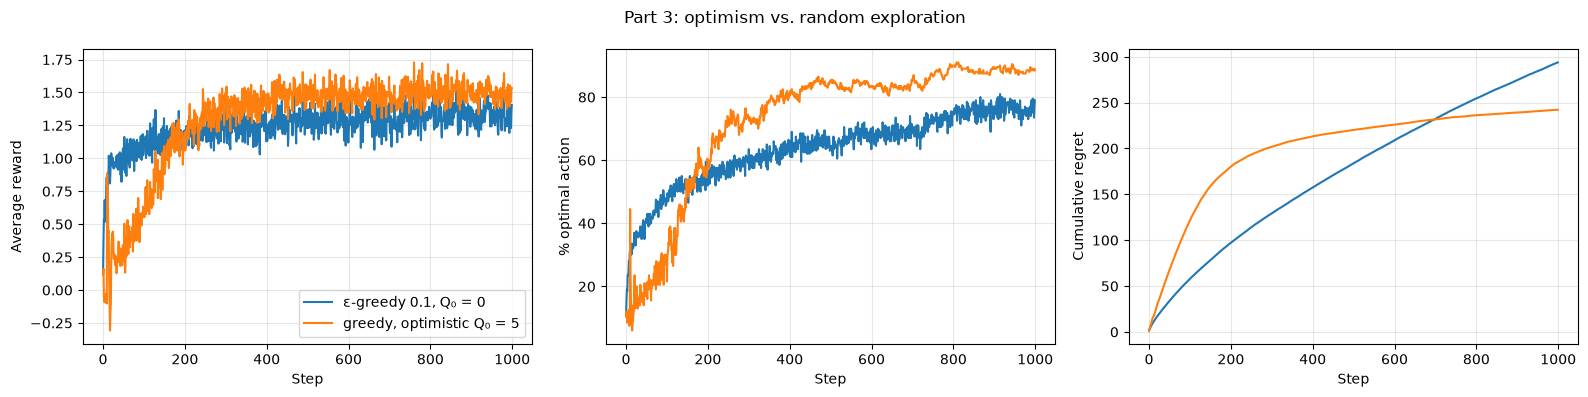

agent                         avg reward   % optimal   total regret
                              (last 100)  (last 100)        (final)
ε-greedy 0.1, Q₀ = 0                1.33        76.5          293.7
greedy, optimistic Q₀ = 5           1.49        88.6          242.1


In [19]:
def constant_step(alpha):
    return lambda Q, N, arm, reward: update_constant_step(Q, N, arm, reward, alpha)


results_p3 = {
    "ε-greedy 0.1, Q₀ = 0":      run_many(eps_greedy(0.1), constant_step(0.1), q_init=0.0),
    "greedy, optimistic Q₀ = 5": run_many(eps_greedy(0.0), constant_step(0.1), q_init=5.0),
}
plot_all(results_p3, "Part 3: optimism vs. random exploration")
print_summary(results_p3)

### 3.3 📝 Understanding optimism (6 points)

**(a)** *(3 pts)* The optimistic agent's "% optimal action" curve typically shows an early **spike followed by a dip** before it climbs. Explain in your own words what the agent is doing in the first ~20 steps and why the curve behaves this way. (Think: what happens to the estimate of an arm right after it is tried?)

**✏️ Your answer:**

All arms start with equal optimistic estimates higher than their true values. The early spike occurs because the agent breaks initial ties randomly, occasionally picking the optimal arm by chance. The dip happens because pulling the optimal arm yields a reward lower than its optimistic estimate, dropping its Q-value. The greedy agent then temporarily abandons it to explore all other un-pulled arms that still have higher optimistic estimates. Once all arms are tried the curve climbs back up.

**(b)** *(1 pt)* The optimistic agent uses ε = 0. Where does its exploration come from?

**✏️ Your answer:**

Exploration comes from the initial optimistic values. Because the arms are initialized to values higher than their true ones, the agent is forced to explore every arm initially. whenever an arm is tried, its estimated value drops due to disappointing rewards, causing the agent to switch and try other unpulled arms until all of them have been explored.

**(c)** *(2 pts)* Describe **one situation** where optimistic initial values would *not* be a good way to explore. (Hint: what happens after the initial optimism has faded? Or what if you do not know how large rewards can be?)

**✏️ Your answer:**

After Initial optimism has faded we will only keep exploiting the highest Q so if it stayed better than the others even though it is not the optimal we will be stuck with it unless we got disappointed. If we don't know how large rewards can be, then we might put Q values that are too optimistic and that will make the training need lots of steps to reach the true values.

---
# Part 4: Upper Confidence Bound (UCB) (10 points)

Random exploration has a weakness: it wastes pulls on arms that are already known to be bad. **UCB** explores *intelligently* by adding a bonus to arms that are **uncertain**, meaning arms that have been tried only a few times:

$$A_t = \arg\max_a \left[\, Q_t(a) + c\sqrt{\frac{\ln t}{N_t(a)}} \,\right]$$

* $Q_t(a)$: the current estimate (the "exploit" part);
* $c\sqrt{\ln t / N_t(a)}$: the **uncertainty bonus** (the "explore" part). It is large when $N_t(a)$ is small and shrinks as the arm is pulled more;
* $c$ controls how much the agent values exploring;
* $\ln$ is the natural logarithm (`np.log`), and $t$ is the current step number.

An arm with $N_t(a) = 0$ has an undefined (infinite) bonus, so UCB simply **tries every untried arm first**.

### 4.1 🛠️ Write `ucb_action` (3 points)

Write `ucb_action(Q, N, t, c, rng)`:

1. If any arm has `N == 0`, return one of the untried arms (chosen uniformly at random).
2. Otherwise compute the score $Q + c\sqrt{\ln t / N}$ for every arm and return the arm with the highest score (ties broken randomly).

In [38]:
def ucb_action(Q, N, t, c, rng):
    # Q, N: arrays (one entry per arm); t: current step number (starts at 1); c: exploration strength.

    # TODO: your code here
    zero_tries_arms = []
    for i in range(len(N)):
        if N[i] == 0:
            zero_tries_arms.append(i)

    if len(zero_tries_arms) != 0:
        return rng.choice(zero_tries_arms)
    else:
        z = []
        for i in range(len(Q)):
            z.append(Q[i] + c * (np.sqrt(np.log(t) / N[i])))
        return argmax_random_ties(z, rng)

In [39]:
# ✅ Test cell
def test_ucb_action():
    rng = np.random.default_rng(0)
    a = ucb_action(np.array([5.0, 5.0, 5.0]), np.array([3, 0, 2]), 6, 2.0, rng)
    assert a == 1, "an arm that has never been tried (N = 0) must be chosen first"
    a = ucb_action(np.array([1.0, 1.0, 1.0]), np.array([50, 50, 2]), 102, 2.0, rng)
    assert a == 2, "with equal Q, the least-tried arm has the biggest bonus and should be chosen"
    a = ucb_action(np.array([9.0, 0.0, 9.0]), np.array([5, 0, 5]), 11, 1.0, rng)
    assert a == 1, "an untried arm must be chosen first, even if the other arms have much higher estimates"
    a = ucb_action(np.array([1.0, 3.0, 2.0]), np.array([10, 10, 10]), 30, 2.0, rng)
    assert a == 1, "with equal counts, the arm with the highest Q should be chosen"
    # The bonus must use the NATURAL logarithm of t (np.log), not log10 or log2:
    a = ucb_action(np.array([1.0, 2.0]), np.array([1, 4]), 200, 1.0, rng)
    assert a == 0, "t = 200, c = 1: scores are 1 + sqrt(ln 200 / 1) = 3.30 and 2 + sqrt(ln 200 / 4) = 3.15, so arm 0 wins (use np.log)"
    a = ucb_action(np.array([1.0, 2.0]), np.array([1, 4]), 20, 1.0, rng)
    assert a == 1, "t = 20, c = 1: scores are 1 + sqrt(ln 20 / 1) = 2.73 and 2 + sqrt(ln 20 / 4) = 2.87, so arm 1 wins (use np.log)"
    a = ucb_action(np.array([1.0, 3.0, 2.0]), np.array([1, 50, 100]), 151, 0.0, rng)
    assert a == 1, "with c = 0 there is no bonus, so UCB is purely greedy"
    a = ucb_action(np.array([0.0, 1.0]), np.array([1, 100]), 101, 1.0, rng)
    assert a == 0, "scores are 0 + sqrt(ln 101 / 1) = 2.15 and 1 + sqrt(ln 101 / 100) = 1.21, so arm 0 wins"
    print("✅ ucb_action passed")

run_test(test_ucb_action)

✅ ucb_action passed


### 4.2 Experiment (3 points)

*Provided.* Compare UCB with the best ε-greedy from Part 2 and with the optimistic agent from Part 3. We try two values of $c$.

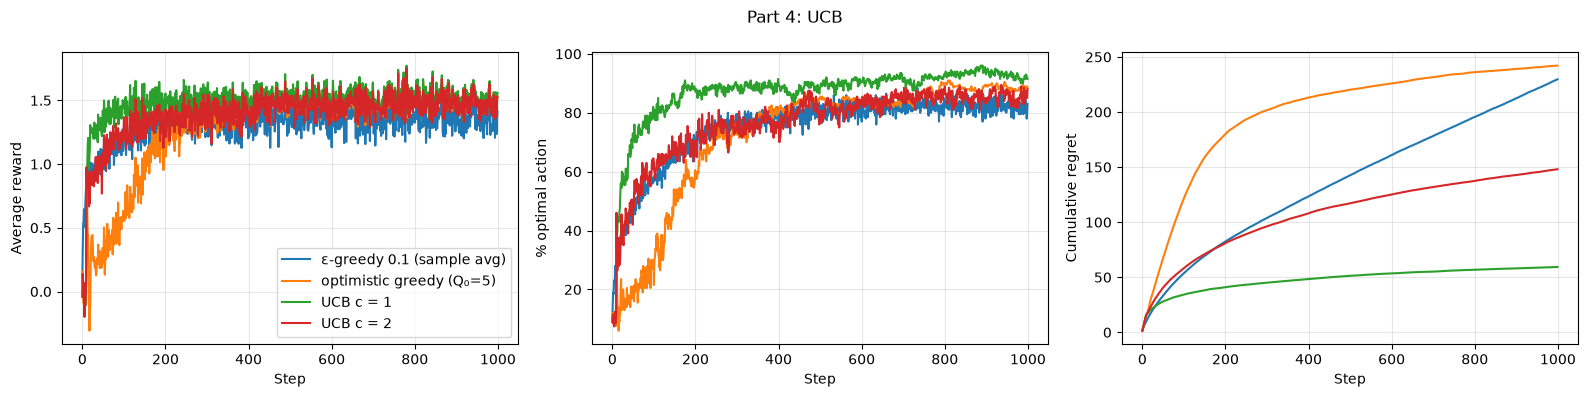

agent                         avg reward   % optimal   total regret
                              (last 100)  (last 100)        (final)
ε-greedy 0.1 (sample avg)           1.35        82.3          229.7
optimistic greedy (Q₀=5)            1.49        88.6          242.1
UCB c = 1                           1.51        92.8           59.4
UCB c = 2                           1.47        85.7          148.1


In [40]:
def ucb(c):
    return lambda Q, N, t, rng: ucb_action(Q, N, t, c, rng)


results_p4 = {
    "ε-greedy 0.1 (sample avg)": results_p2["ε-greedy (0.1)"],
    "optimistic greedy (Q₀=5)":  results_p3["greedy, optimistic Q₀ = 5"],
    "UCB c = 1":                 run_many(ucb(1.0), update_sample_average),
    "UCB c = 2":                 run_many(ucb(2.0), update_sample_average),
}
plot_all(results_p4, "Part 4: UCB")
print_summary(results_p4)

### 4.3 📝 Understanding UCB (4 points)

**(a)** *(2 pts)* In your own words, 
- What does the bonus term do? 
- What happens to the bonus of an arm that is pulled again and again? 
- What happens to the bonus of an arm that is *not* pulled for a long time while $t$ keeps growing?

**✏️ Your answer:**

- Encourages exploration of untried arms
- Decreases since we are dividing by the number of times we tried the arm, so the uncertainity term will decrease
- Increases since we have ln(t) in the numerator while c and n are constant

**(b)** *(2 pts)* Based on your results,
- How does UCB compare with ε-greedy (ε = 0.1) in terms of regret? Give a reason for the difference.
- Then say what UCB does when $c = 0$, 
- and what it does when $c$ is extremely large.

**✏️ Your answer:**

- As we go in time, the epsilon greedy still have a 10% chance to explore, while UCB with the increase in time the uncertainity term is negligible so it focuses on the learnt best arm.
- It will be a greedy epsilon with epsilon = 0
- It will give precedence to exploration, even if it found the best arm.

---
# Part 5: When the world changes: non-stationary bandits (10 points)

In many real problems the best choice **changes** over time (tastes change, prices move, machines wear out). We model this with a *drifting* bandit: after every pull, every arm's true value takes a small random step (standard deviation 0.02). All arms start with the same value 0, and the best arm changes over time.

We compare, all with ε = 0.1:

* **sample-average** updates (every past reward counts equally), and
* **constant step size** $\alpha = 0.1$ (recent rewards count more).

We also test **UCB** (with sample average) to see whether its confidence bonus still makes sense.

### 5.1 Experiment (3 points)

*Provided.* This takes about a minute.

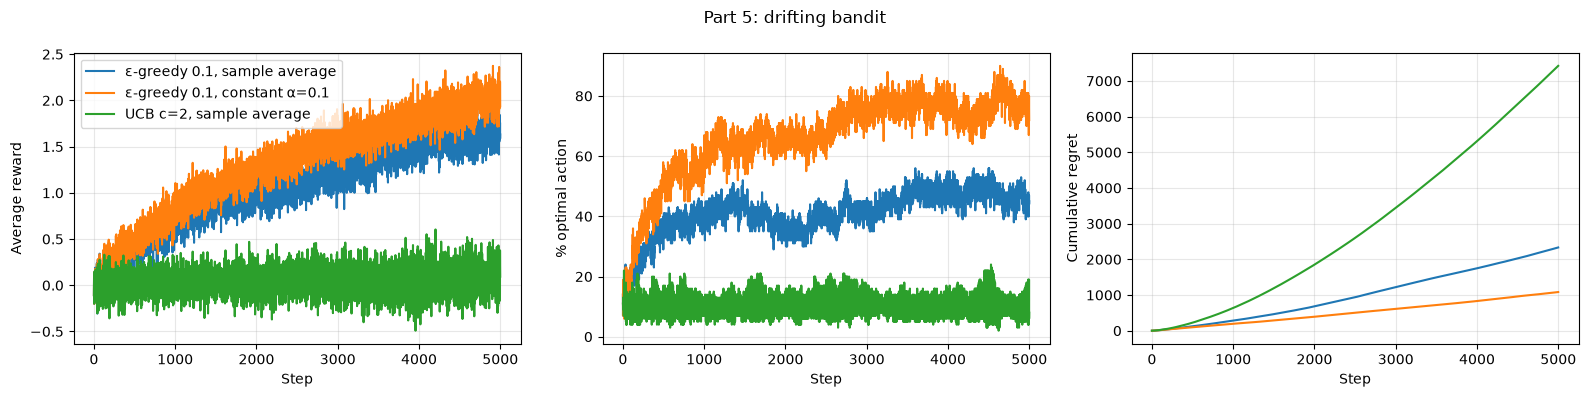

agent                         avg reward   % optimal   total regret
                             (last 1000) (last 1000)        (final)
ε-greedy 0.1, sample average        1.60        47.6         2332.1
ε-greedy 0.1, constant α=0.1        1.93        76.3         1083.1
UCB c=2, sample average             0.07        10.0         7420.0


In [23]:
N_RUNS_NS, N_STEPS_NS, DRIFT = 100, 5000, 0.02

results_p5 = {
    "ε-greedy 0.1, sample average": run_many(eps_greedy(0.1), update_sample_average, n_runs=N_RUNS_NS,
                                             n_steps=N_STEPS_NS, drift_std=DRIFT, equal_start=True),
    "ε-greedy 0.1, constant α=0.1": run_many(eps_greedy(0.1), constant_step(0.1), n_runs=N_RUNS_NS,
                                             n_steps=N_STEPS_NS, drift_std=DRIFT, equal_start=True),
    "UCB c=2, sample average":      run_many(ucb(2.0), update_sample_average, n_runs=N_RUNS_NS,
                                             n_steps=N_STEPS_NS, drift_std=DRIFT, equal_start=True),
}
plot_all(results_p5, "Part 5: drifting bandit")
print_summary(results_p5, last=1000)

### 5.2 📝 Why sample averages struggle (4 points)

Explain, in your own words, why the **sample-average** agent does much worse than the **constant step-size** agent in a changing world. Refer to *how much weight each update gives to old vs. new rewards* (look at the step size $1/n$ as $n$ grows). *(About 80 to 120 words.)*

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer (about 80 to 120 words).)*

### 5.3 📝 Does UCB survive change? (3 points)

Look at the UCB curve in the drifting world. Is it better or worse than the sample-average ε-greedy agent, and better or worse than the constant-step agent? Explain why UCB, as we implemented it, is not well suited to a changing world. *(About 60 to 100 words.)*

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer (about 60 to 100 words).)*

---
# Part 6: Exploration when actions have delayed effects: RiverSwim (16 points)

In a bandit, each pull is independent. In a **Markov decision process (MDP)** your actions also move you between *states*, so a good outcome may only be reachable after a whole **sequence** of actions. Random exploration then becomes much less effective. You will see this in **RiverSwim**, a classic hard-exploration problem.

### The environment

A swimmer is in a river with **6 states** in a line. The swimmer starts in state 1 (leftmost) and can choose **left** (swim with the current) or **right** (swim against it):

```
   +0.005 if you choose LEFT here             +1.0 if you choose RIGHT here
            ↓                                              ↓
         [ s1 ] ⇄ [ s2 ] ⇄ [ s3 ] ⇄ [ s4 ] ⇄ [ s5 ] ⇄ [ s6 ]
```

* **Left** always works: you move one state left (in s1 you stay).
* **Right** is hard. In the middle states s2 to s5: 35% you move right, 60% you stay, 5% you get pushed left. In s1: 40% move right, 60% stay. In s6: 60% stay, 40% pushed left.
* **Rewards:** a small **+0.005** for choosing *left* in s1 (an easy, tempting reward) and a large **+1.0** for choosing *right* in s6 (hard to reach). Everything else gives 0.

The best long-term strategy is to swim right all the way to s6 and stay there, but you must *explore* to discover this.

We will use **Q-learning** with a table `Q[state, action]` (action 0 = left, 1 = right), $\alpha = 0.1$ and discount $\gamma = 0.95$.

### 6.1 🛠️ Q-learning update (4 points)

Write `q_learning_update(Q, s, a, r, s_next, alpha, gamma)` implementing
$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[\, r + \gamma \max_{a'} Q(s', a') - Q(s,a) \,\big].$$
Modify the array `Q` in place (only the entry `Q[s, a]` changes).

In [24]:
def q_learning_update(Q, s, a, r, s_next, alpha, gamma):
    # Q has shape (n_states, n_actions). Update Q[s, a] in place.

    # TODO: your code here
    raise NotImplementedError

In [25]:
# ✅ Test cell
def test_q_learning_update():
    Q = np.zeros((3, 2)); Q[2] = [0.0, 4.0]
    before = Q.copy()
    q_learning_update(Q, 0, 1, 1.0, 2, 0.5, 0.9)
    # target = 1 + 0.9 * max(0, 4) = 4.6 ;  Q[0,1] = 0 + 0.5 * 4.6 = 2.3
    assert np.isclose(Q[0, 1], 2.3), f"expected Q[0,1] = 2.3, got {Q[0, 1]}"
    Q[0, 1] = before[0, 1]
    assert np.array_equal(Q, before), "only the entry Q[s, a] may change"
    print("✅ q_learning_update passed")

run_test(test_q_learning_update)

⚠️  test_q_learning_update: function not implemented yet


### 6.2 🛠️ Choosing actions in an MDP (2 points)

You already have two ways to choose actions. Now **reuse them** for a single state. Write `select_action_mdp(agent, Q_s, N_s, t, rng)` where

* `Q_s` and `N_s` are the value estimates and visit counts **for the current state only** (arrays of length 2, one per action "left" or "right");
* `agent` is a dictionary: `{"type": "epsilon", "epsilon": 0.1}` means ε-greedy, and `{"type": "ucb", "c": 2.0}` means UCB. Any other type should `raise ValueError`.

Just call your existing `epsilon_greedy_action` or `ucb_action`.

In [26]:
def select_action_mdp(agent, Q_s, N_s, t, rng):
    # TODO: your code here
    raise NotImplementedError

In [27]:
# ✅ Test cell
def test_select_action_mdp():
    rng = np.random.default_rng(0)
    a = select_action_mdp({"type": "epsilon", "epsilon": 0.0}, np.array([0.2, 0.9]), np.array([3, 3]), 7, rng)
    assert a == 1, "epsilon = 0 should pick the action with the higher Q"
    a = select_action_mdp({"type": "ucb", "c": 2.0}, np.array([0.2, 0.9]), np.array([0, 5]), 7, rng)
    assert a == 0, "UCB must try the never-tried action first"
    try:
        select_action_mdp({"type": "banana"}, np.zeros(2), np.zeros(2, dtype=int), 1, rng)
        assert False, "an unknown agent type should raise ValueError"
    except ValueError:
        pass
    print("✅ select_action_mdp passed")

run_test(test_select_action_mdp)

⚠️  test_select_action_mdp: function not implemented yet


### 6.3 Experiment (4 points)

*Provided.* Four agents, each run for 30,000 steps on 5 different random seeds (about 10 to 20 seconds):

| Agent | Idea |
|---|---|
| ε-greedy, ε = 0.1 | random exploration, starts with $Q = 0$ |
| ε-greedy, ε = 0.3 | *more* random exploration |
| Optimistic, $Q_0 = 20$ | greedy, but every $Q$ starts very high (the largest possible value is $1/(1-\gamma) = 20$) |
| UCB, $c = 2$ | your UCB rule, applied in each state separately |

The plots show the average reward per step over time, and **the fraction of time spent in each state** during the last 5,000 steps.

In [28]:
class RiverSwim:
    n_states, n_actions = 6, 2          # actions: 0 = left, 1 = right

    def __init__(self, rng):
        self.rng, self.s = rng, 0

    def reset(self):
        self.s = 0
        return self.s

    def step(self, a):
        s = self.s
        if a == 0:                                           # LEFT: always works
            r, s_next = (0.005 if s == 0 else 0.0), max(s - 1, 0)
        else:                                                # RIGHT: against the current
            u = self.rng.random()
            if s == 0:
                s_next = 1 if u < 0.40 else 0
            elif s == 5:
                s_next = 4 if u < 0.40 else 5
            else:
                s_next = s + 1 if u < 0.35 else (s if u < 0.95 else s - 1)
            r = 1.0 if s == 5 else 0.0
        self.s = s_next
        return s_next, r


def run_q_learning(agent, q_init, n_steps=30000, seed=0, alpha=0.1, gamma=0.95, tail=5000):
    rng = np.random.default_rng(seed)
    env = RiverSwim(rng)
    Q = np.full((6, 2), q_init, dtype=float)
    N = np.zeros((6, 2), dtype=int)
    s = env.reset()
    rewards = np.zeros(n_steps)
    visits = np.zeros(6)
    for t in range(n_steps):
        a = select_action_mdp(agent, Q[s], N[s], t + 1, rng)
        s_next, r = env.step(a)
        N[s, a] += 1
        q_learning_update(Q, s, a, r, s_next, alpha, gamma)
        rewards[t] = r
        if t >= n_steps - tail:
            visits[s] += 1
        s = s_next
    return rewards, visits / tail


AGENTS = {
    "ε-greedy (ε=0.1)":   dict(agent={"type": "epsilon", "epsilon": 0.1}, q_init=0.0),
    "ε-greedy (ε=0.3)":   dict(agent={"type": "epsilon", "epsilon": 0.3}, q_init=0.0),
    "Optimistic (Q₀=20)": dict(agent={"type": "epsilon", "epsilon": 0.0}, q_init=20.0),
    "UCB (c=2)":          dict(agent={"type": "ucb", "c": 2.0},           q_init=0.0),
}
SEEDS = range(5)

rs_rewards, rs_visits = {}, {}
for name, cfg in AGENTS.items():
    out = [run_q_learning(seed=sd, **cfg) for sd in SEEDS]
    rs_rewards[name] = np.mean([o[0] for o in out], axis=0)
    rs_visits[name]  = np.mean([o[1] for o in out], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
w = 1000                                                      # moving-average window
for name, rew in rs_rewards.items():
    axes[0].plot(np.convolve(rew, np.ones(w) / w, mode="valid"), label=name)
axes[0].set_xlabel("Training step"); axes[0].set_ylabel(f"Average reward per step ({w}-step window)")
axes[0].set_title("Learning curves"); axes[0].legend()
width = 0.2
for i, (name, vis) in enumerate(rs_visits.items()):
    axes[1].bar(np.arange(1, 7) + (i - 1.5) * width, vis, width, label=name)
axes[1].set_xlabel("State (s1 ... s6)"); axes[1].set_ylabel("Fraction of time (last 5000 steps)")
axes[1].set_title("Where does each agent spend its time?"); axes[1].legend()
plt.tight_layout(); plt.show()

for name in AGENTS:
    print(f"{name:<22} average reward per step over the last 5000 steps: {rs_rewards[name][-5000:].mean():.3f}")

NotImplementedError: 

*Provided.* One more experiment: how optimistic does the initial value need to be? Every agent below is purely greedy ($\varepsilon = 0$) and differs only in $Q_0$.

In [ ]:
print(f"{'Q0':>6}  {'avg reward per step (last 5000)':>34}")
for q0 in [0.0, 1.0, 5.0, 20.0]:
    out = [run_q_learning({"type": "epsilon", "epsilon": 0.0}, q0, seed=sd)[0][-5000:].mean() for sd in SEEDS]
    print(f"{q0:>6.1f}  {np.mean(out):>34.3f}")

### 6.4 📝 Analysis (6 points)

**(a)** *(2 pts)* Using the state-visitation plot, describe in one or two sentences what the two ε-greedy agents ended up doing, and why raising ε from 0.1 to 0.3 did **not** fix the problem. (Think about the reward of +0.005 that the agent finds first.)

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer.)*

**(b)** *(2 pts)* **Estimate** how unlikely it is for ε-greedy (ε = 0.1) to stumble on the big reward. Suppose the agent's greedy action is "left" everywhere, so it only goes right when it explores. Each step, it picks a random action with probability ε = 0.1 and that random action is "right" with probability 1/2, so it goes right with probability **0.05**. To go from s1 to s6 the agent needs five successful "right" moves in a row. Compute the probability of the next **five** actions all being "right" **and** all five moves succeeding (use success probabilities 0.4 for the move from s1, then 0.35 for each of the following four moves). Write the calculation in the code cell below and comment on the result.

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer.)*

In [ ]:
# (b) Write your calculation here.
p_go_right = 0.05      # probability that an exploratory step picks "right" at a given moment

# TODO: compute the probability of five consecutive "right" actions that all succeed
prob = None
print("Probability:", prob)

**(c)** *(2 pts)* Optimism and UCB both solve RiverSwim, while random exploration does not. In your own words, what do they do differently? Then use the $Q_0$ table above: how optimistic must the starting value be? (Name one downside of relying on optimism or UCB in a very large problem, for example a video game with millions of different states.)

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer.)*

---
# Part 7: Reflection (6 points)

Answer **one** of the following questions in about 100 words.

**Option A.** A streaming service must decide which thumbnail image to show each viewer for a new film. It can show the thumbnail that has worked best so far (exploit) or test others (explore). Which method from this assignment (ε-greedy, optimism, UCB) would you use and why? What could go wrong in practice (think about how people's tastes change, and about the cost of showing a bad thumbnail)?

**Option B.** In some real problems, *exploring is dangerous*: a robot next to people, or a doctor choosing a treatment. What is wrong with exploring randomly in such settings? Suggest one way to make exploration safer.

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer (about 100 words).)*

---
# Part 8: a decaying ε (5 points)

A constant ε keeps exploring forever (Part 1.5). A better idea is to explore a lot **at first** and **less as the agent learns**.

**(a)** Write a function `epsilon_schedule(t)` that returns an ε that starts near 1 and **decreases** as the step number $t$ grows, but never below a small minimum (for example 0.01). Any sensible formula is fine, for example $\varepsilon_t = \max(0.01,\ 1/\sqrt{t})$.

In [ ]:
def epsilon_schedule(t):
    # TODO: return the value of epsilon to use at step t (t = 1, 2, 3, ...)
    raise NotImplementedError

**(b)** Run it in the cell below (already set up) and compare it with the fixed ε = 0.1 agent using the plots and table.

In [ ]:
decaying = lambda Q, N, t, rng: epsilon_greedy_action(Q, epsilon_schedule(t), rng)

results_bonus = {
    "ε-greedy fixed 0.1":  results_p2["ε-greedy (0.1)"],
    "ε-greedy decaying":   run_many(decaying, update_sample_average),
}
plot_all(results_bonus, "Bonus: fixed vs. decaying ε")
print_summary(results_bonus)

**(c)** In 3 or 4 sentences: did it help? What are the risks of decaying ε too fast?

**✏️ Your answer:**

*(Double-click this cell and replace this text with your answer.)*

---
## Before you submit: checklist

- [ ] *Kernel → Restart & Run All* runs without errors from top to bottom.
- [ ] All ✅ test cells print "passed".
- [ ] Every 📝 question has an answer written in your own words.
- [ ] Your name and student ID are filled in at the top.
- [ ] You saved the notebook and (if your instructor asks) exported it to PDF as well.

**Academic integrity.** *[Instructor: insert your policy on collaboration and use of AI tools.]* You may discuss ideas with classmates, but the code and written answers you submit must be your own. Cite any sources you used.